<a href="https://colab.research.google.com/github/quarcs-lab/geo4cambodia/blob/main/notebooks/districts202_gdppc_esda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# District-level GDP per capita in Cambodia, 1990–2022: exploratory spatial data analysis

Part of the [GeoDevelopment Observatory of Cambodia](https://quarcs-lab.github.io/geo4cambodia/).

In [1]:
# Install only what this environment lacks (Colab lacks most of these; a local `uv sync` has them all).
# geo4cambodia loads the data of the observatory; splot brings esda and libpysal.
import importlib.util

missing = [p for p in ("geo4cambodia", "contextily", "splot", "mapclassify") if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
# Importing necessary libraries for data analysis and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns
sns.set(style="darkgrid", context="paper", font_scale=1.02)  # Setting seaborn styles

import plotly.express as px

# Importing libraries for spatial data and visualization
import geopandas as gpd
import contextily as cx

import libpysal
from libpysal import weights
from libpysal.weights import Queen

# Exploratory Spatial Data Analysis (ESDA) tools
import mapclassify as mc
from mapclassify import FisherJenks
import esda
from esda.moran import Moran, Moran_Local

# Spatial plotting tools
import splot
from splot.esda import moran_scatterplot, plot_moran, lisa_cluster
from splot.libpysal import plot_spatial_weights

# Suppressing warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# Adjust the plotting bins
import matplotlib.patches as mpatches

# Set the plotting style
sns.set_style('whitegrid')

In [3]:
import geo4cambodia as geo

# One row per district, one column per year of trend400_ln_y, with names and boundaries
wide = geo.load('gdppc', wide='trend400_ln_y')
provinces = geo.units('province')[['geo_id', 'name']].rename(columns={'geo_id': 'parent_id', 'name': 'province'})
names = (geo.units('district')[['geo_id', 'name', 'parent_id']].rename(columns={'name': 'district'})
         .merge(provinces, on='parent_id').drop(columns='parent_id'))
gdf_wide = geo.boundaries('district')[['geo_id', 'geometry']].merge(names, on='geo_id').merge(wide, on='geo_id')
gdf_wide.insert(0, 'id', range(1, len(gdf_wide) + 1))  # integer ids for the spatial weights below
gdf_wide

,id,geo_id,geometry,district,province,trend400_ln_y1990,trend400_ln_y1991,trend400_ln_y1992,trend400_ln_y1993,trend400_ln_y1994,...,trend400_ln_y2013,trend400_ln_y2014,trend400_ln_y2015,trend400_ln_y2016,trend400_ln_y2017,trend400_ln_y2018,trend400_ln_y2019,trend400_ln_y2020,trend400_ln_y2021,trend400_ln_y2022
0,1,KH-01-01,"MULTIPOLYGON (((102.6339 13.5608, 102.64 13.56...",Malai,Banteay Meanchey,6.428658,6.462579,6.496720,6.531558,6.567528,...,7.731416,7.779222,7.822306,7.860705,7.894797,7.925418,7.953499,7.979897,8.005453,8.030753
1,2,KH-01-02,"MULTIPOLYGON (((103.1478 13.4119, 103.1242 13....",Mongkol Borei,Banteay Meanchey,7.072807,7.114497,7.155954,7.196684,7.236302,...,8.055112,8.094150,8.130964,8.164890,8.195806,8.223975,8.249723,8.273773,8.296987,8.320012
2,3,KH-01-03,"MULTIPOLYGON (((102.8301 13.4868, 102.8165 13....",Ou Chrov,Banteay Meanchey,7.579964,7.604713,7.629385,7.653839,7.677865,...,8.251822,8.290260,8.329432,8.368803,8.407856,8.445896,8.482479,8.517517,8.551438,8.585001
3,4,KH-01-04,"MULTIPOLYGON (((102.7179 13.568, 102.7163 13.5...",Paoy Paet,Banteay Meanchey,7.186116,7.174187,7.162547,7.151818,7.142993,...,8.310897,8.389999,8.465601,8.538016,8.607558,8.674668,8.739924,8.803958,8.867444,8.930739
4,5,KH-01-05,"MULTIPOLYGON (((103.3082 13.6782, 103.2996 13....",Phnum Srok,Banteay Meanchey,6.459087,6.496592,6.534110,6.571653,6.609190,...,7.599007,7.656190,7.714857,7.774929,7.836202,7.898441,7.961285,8.024385,8.087634,8.150868
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
197,198,KH-25-03,"MULTIPOLYGON (((106.3307 11.6872, 106.3274 11....",Memot,Tbong Khmum,6.516580,6.546187,6.575860,6.605836,6.636480,...,7.688862,7.743946,7.797285,7.848637,7.897878,7.945050,7.990439,8.034572,8.078074,8.121458
198,199,KH-25-04,"MULTIPOLYGON (((105.6613 11.7401, 105.6573 11....",Ou Reang Ov,Tbong Khmum,6.293991,6.349030,6.403951,6.458335,6.511821,...,7.681592,7.744028,7.805094,7.864698,7.922806,7.979487,8.035043,8.089951,8.144558,8.199135
199,200,KH-25-05,"MULTIPOLYGON (((105.8088 11.6012, 105.807 11.6...",Ponhea Kraek,Tbong Khmum,6.342667,6.381251,6.419887,6.458652,6.497598,...,7.663494,7.741661,7.818891,7.895283,7.970808,8.045280,8.118502,8.190371,8.261145,8.331176
200,201,KH-25-06,"MULTIPOLYGON (((105.6263 11.9703, 105.6268 11....",Suong,Tbong Khmum,7.255817,7.265754,7.275867,7.286196,7.296869,...,7.838694,7.845570,7.850566,7.855076,7.860336,7.866986,7.875232,7.885140,7.896389,7.908331


In [4]:
# Identify wide columns
value_vars = [col for col in gdf_wide.columns if col.startswith("trend400_ln_y")]

# Reshape to long
gdf_long = gdf_wide.melt(
    id_vars=[col for col in gdf_wide.columns if col not in value_vars],  # keep IDs + geometry
    value_vars=value_vars,
    var_name="year_var",
    value_name="trend400_ln_y"
)

# Extract year from the variable name
gdf_long["year"] = gdf_long["year_var"].str.extract(r"(\d{4})").astype(int)

# Drop the original wide-style column name
gdf_long = gdf_long.drop(columns="year_var")

# Ensure it's still a GeoDataFrame
gdf_long = gdf_long.set_geometry("geometry")

# Optional: sort for tidy panel structure
gdf_long = gdf_long.sort_values(["id", "year"]).reset_index(drop=True)

In [5]:
gdf_long

,id,geo_id,geometry,district,province,trend400_ln_y,year
0,1,KH-01-01,"MULTIPOLYGON (((102.6339 13.5608, 102.64 13.56...",Malai,Banteay Meanchey,6.428658,1990
1,1,KH-01-01,"MULTIPOLYGON (((102.6339 13.5608, 102.64 13.56...",Malai,Banteay Meanchey,6.462579,1991
2,1,KH-01-01,"MULTIPOLYGON (((102.6339 13.5608, 102.64 13.56...",Malai,Banteay Meanchey,6.496720,1992
3,1,KH-01-01,"MULTIPOLYGON (((102.6339 13.5608, 102.64 13.56...",Malai,Banteay Meanchey,6.531558,1993
4,1,KH-01-01,"MULTIPOLYGON (((102.6339 13.5608, 102.64 13.56...",Malai,Banteay Meanchey,6.567528,1994
...,...,...,...,...,...,...,...
6661,202,KH-25-07,"POLYGON ((105.6675 11.823, 105.6596 11.8281, 1...",Tboung Khmum,Tbong Khmum,7.999124,2018
6662,202,KH-25-07,"POLYGON ((105.6675 11.823, 105.6596 11.8281, 1...",Tboung Khmum,Tbong Khmum,8.065395,2019
6663,202,KH-25-07,"POLYGON ((105.6675 11.823, 105.6596 11.8281, 1...",Tboung Khmum,Tbong Khmum,8.127686,2020
6664,202,KH-25-07,"POLYGON ((105.6675 11.823, 105.6596 11.8281, 1...",Tboung Khmum,Tbong Khmum,8.187005,2021


In [6]:
px.strip(
    gdf_long,
    x="trend400_ln_y",
    y="district",
    color="province",
    animation_frame= 'year',
    range_x = [gdf_long["trend400_ln_y"].min(), gdf_long["trend400_ln_y"].max()],
    hover_name="district",
    hover_data=["province","district","trend400_ln_y"]
)

In [7]:
fig = px.line(
    gdf_long,
    x="year",
    y="trend400_ln_y",
    color="province",
    hover_data=["province", "district","trend400_ln_y"]
)

fig.show()

(np.float64(102.069105),
 np.float64(107.89239500000001),
 np.float64(9.674765),
 np.float64(14.929135))

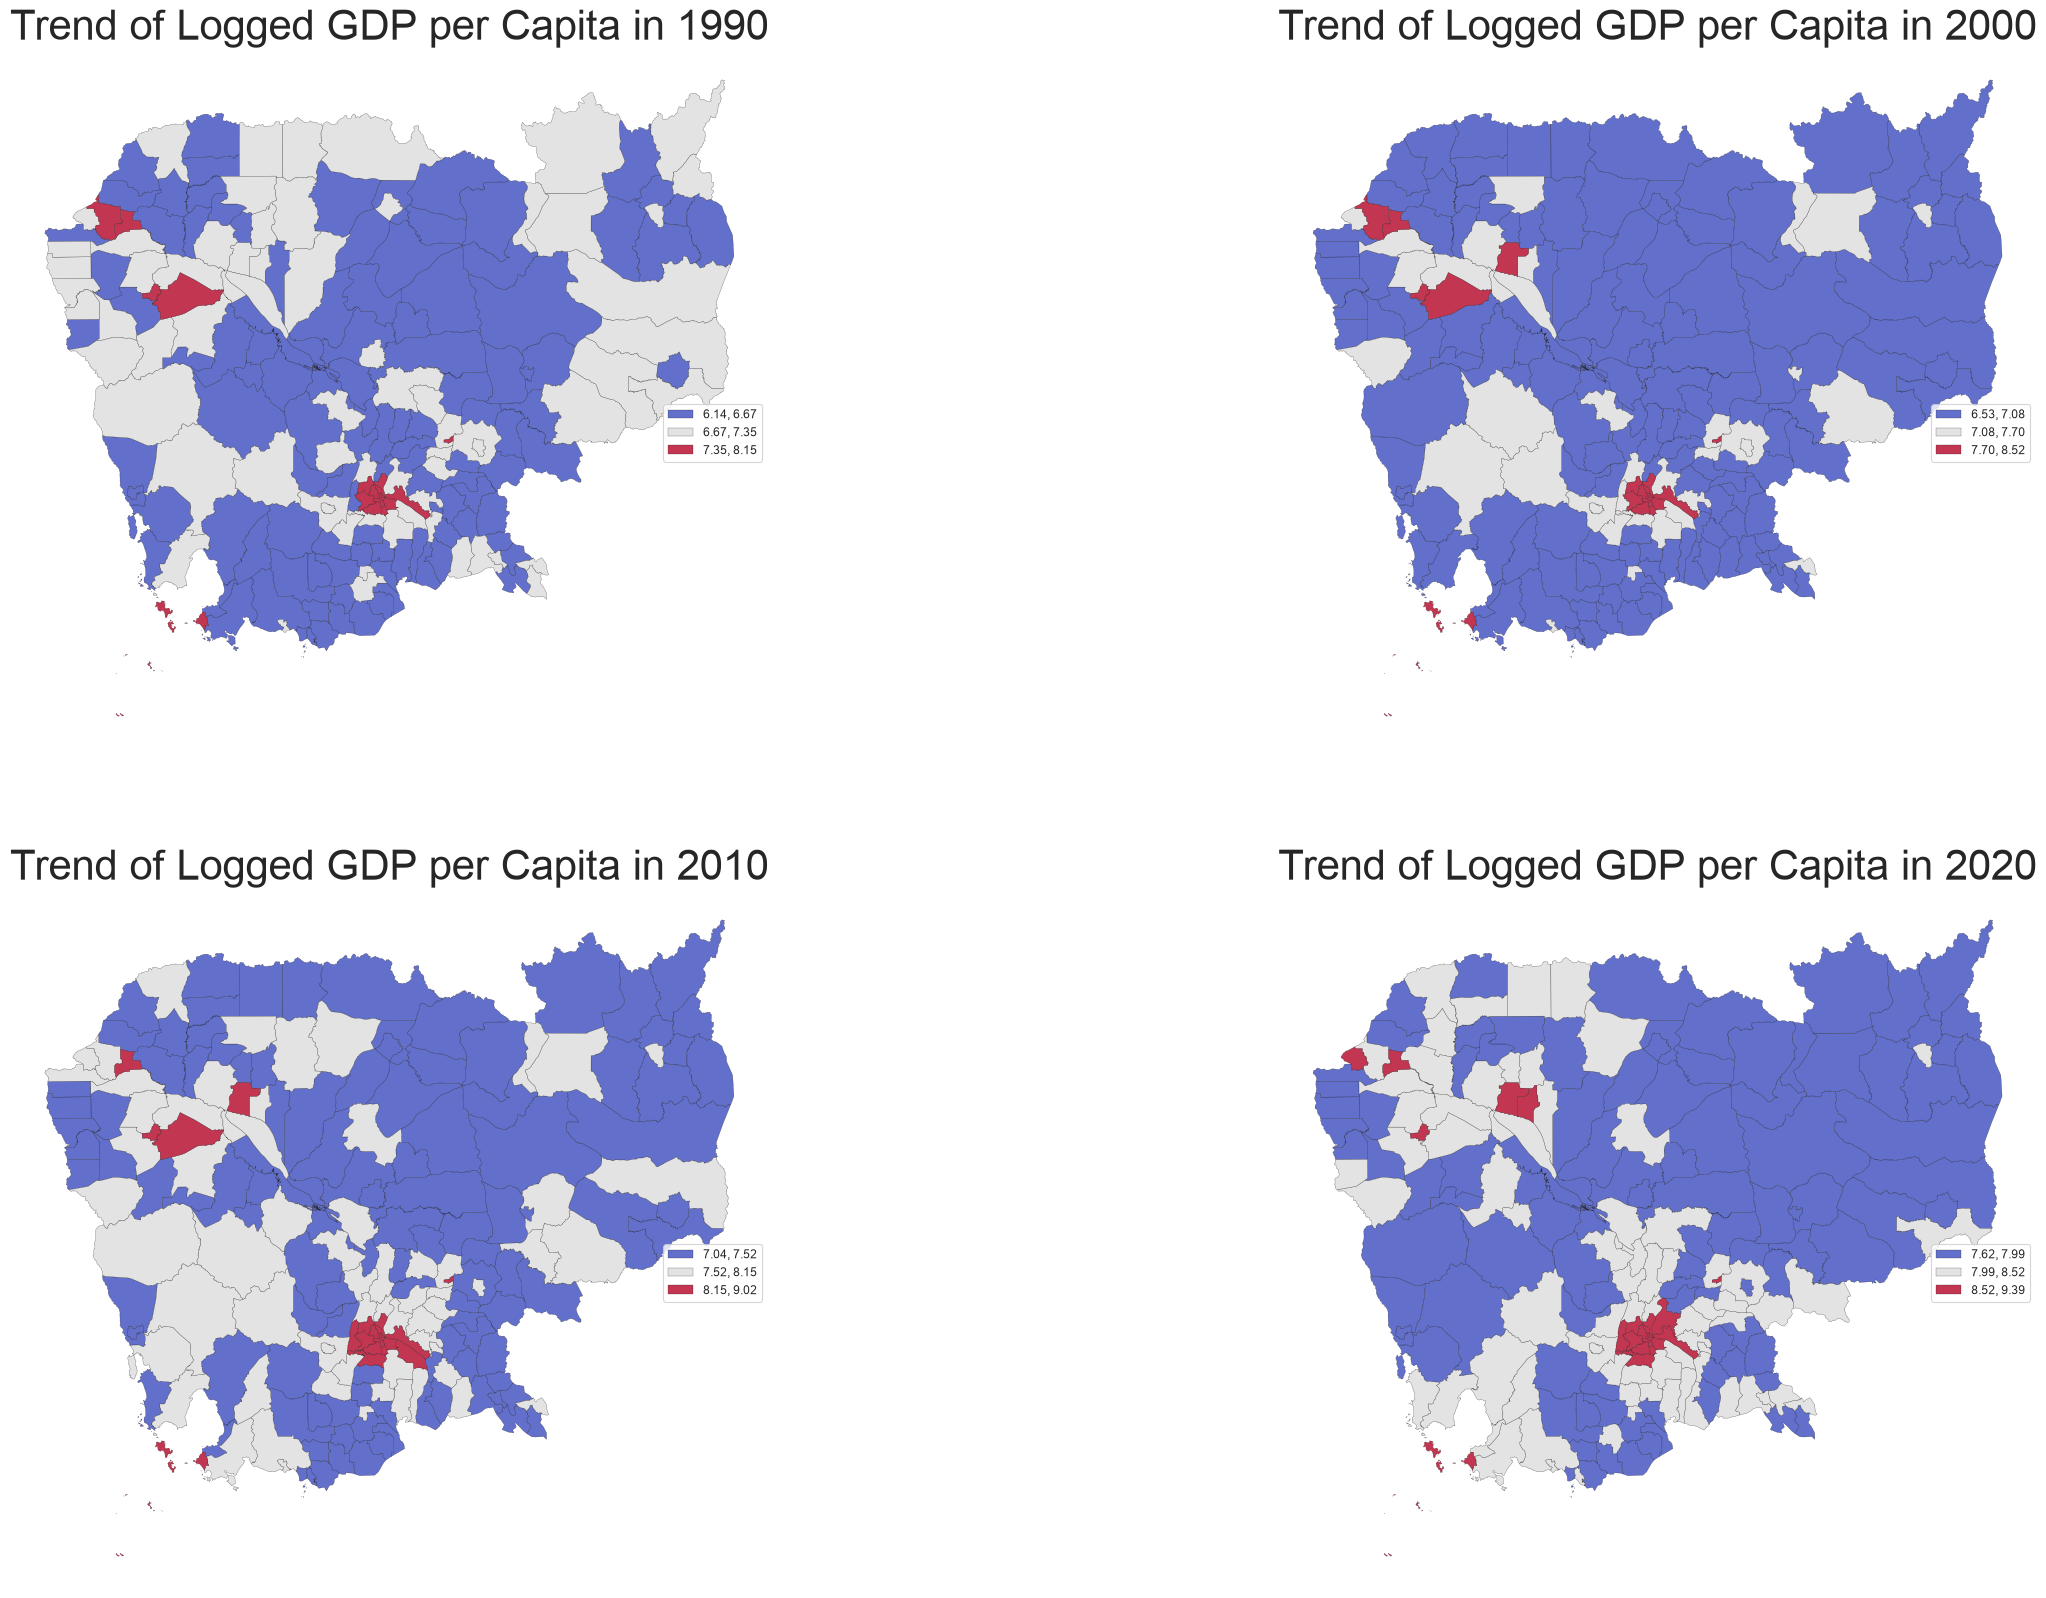

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(30, 20))

gdf_wide.plot(
    column='trend400_ln_y1990',                # Data for coloring
    scheme='FisherJenks',                 # Classification scheme
    k=3,
    cmap='coolwarm',                      # Color map for visualization
    edgecolor='k',                        # Color of edges
    linewidth=0.2,                        # Width of edge lines
    alpha=0.8,                            # Transparency
    legend=True,                          # Show legend
    ax=axes[0,0],                           # Specify the axis for plotting
    legend_kwds={'bbox_to_anchor': (1, 0.5)}  # Legend customization
)
axes[0,0].set_title('Trend of Logged GDP per Capita in 1990', fontsize = 30)
axes[0,0].axis("off")

gdf_wide.plot(
    column='trend400_ln_y2000',                # Data for coloring
    scheme='FisherJenks',                 # Classification scheme
    k=3,
    cmap='coolwarm',                      # Color map for visualization
    edgecolor='k',                        # Color of edges
    linewidth=0.2,                        # Width of edge lines
    alpha=0.8,                            # Transparency
    legend=True,                          # Show legend
    ax=axes[0,1],                           # Specify the axis for plotting
    legend_kwds={'bbox_to_anchor': (1, 0.5)}  # Legend customization
)
axes[0,1].set_title('Trend of Logged GDP per Capita in 2000', fontsize = 30)
axes[0,1].axis("off")

gdf_wide.plot(
    column='trend400_ln_y2010',                # Data for coloring
    scheme='FisherJenks',                 # Classification scheme
    k=3,
    cmap='coolwarm',                      # Color map for visualization
    edgecolor='k',                        # Color of edges
    linewidth=0.2,                        # Width of edge lines
    alpha=0.8,                            # Transparency
    legend=True,                          # Show legend
    ax=axes[1,0],                           # Specify the axis for plotting
    legend_kwds={'bbox_to_anchor': (1, 0.5)}  # Legend customization
)
axes[1,0].set_title('Trend of Logged GDP per Capita in 2010', fontsize = 30)
axes[1,0].axis("off")

gdf_wide.plot(
    column='trend400_ln_y2020',                # Data for coloring
    scheme='FisherJenks',                 # Classification scheme
    k=3,
    cmap='coolwarm',                      # Color map for visualization
    edgecolor='k',                        # Color of edges
    linewidth=0.2,                        # Width of edge lines
    alpha=0.8,                            # Transparency
    legend=True,                          # Show legend
    ax=axes[1,1],                           # Specify the axis for plotting
    legend_kwds={'bbox_to_anchor': (1, 0.5)}  # Legend customization
)
axes[1,1].set_title('Trend of Logged GDP per Capita in 2020', fontsize = 30)
axes[1,1].axis("off")

In [9]:
# Visualize spatial data using the explore() method of a GeoDataFrame
gdf_wide.explore(
    # Specify the column to visualize on the map
    column='trend400_ln_y2022',
    # Specify the attributes to display in the tooltip when hovering over map features
    tooltip=['trend400_ln_y2022', 'district', 'province'],
    # Choose the classification scheme for data visualization
    scheme='fisherjenks',
    # Specify the number of classes for classification
    k=3,
    # Choose the colormap for data visualization
    cmap='coolwarm',
    # Specify whether to display a legend
    legend=True,
    # Choose the basemap tiles provider
    tiles='CartoDB positron',
    # Customize the style of the basemap tiles
    style_kwds=dict(color="gray", weight=0.5),
    # Customize the appearance of the legend
    legend_kwds=dict(colorbar=False)
)

In [10]:
Wqueen = weights.Queen.from_dataframe(gdf_wide, ids = 'id')
W_plot = weights.Queen.from_dataframe(gdf_wide)

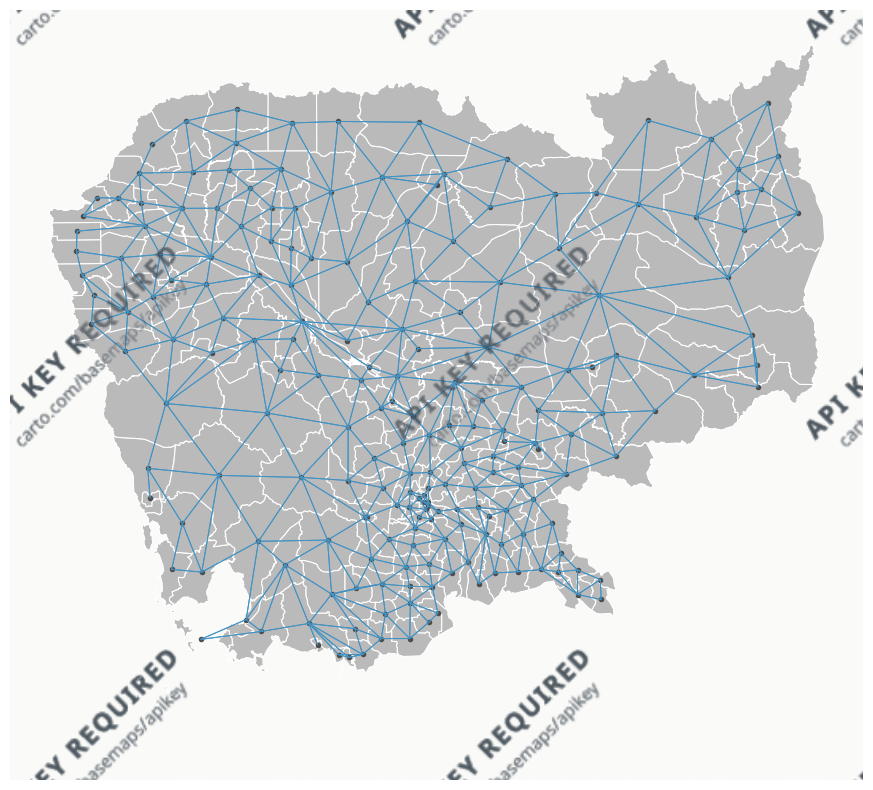

In [11]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(14,10))
plot_spatial_weights(W_plot, gdf_wide, ax=ax)
cx.add_basemap(ax, crs=gdf_wide.crs.to_string(), source = cx.providers.CartoDB.Positron,           attribution=False)
cx.add_basemap(ax, crs=gdf_wide.crs.to_string(), source = cx.providers.CartoDB.PositronOnlyLabels, attribution=False)
plt.show()

In [12]:
# Define a function to calculate moran's I per year
def moran_by_col(y, w=Wqueen):
    mo = esda.Moran(y, w=w)
    mo_s = pd.Series(
        {"I": mo.I, "I-P value": mo.p_sim},
    )
    return mo_s

In [13]:
gdf_wide.columns

Index(['id', 'geo_id', 'geometry', 'district', 'province', 'trend400_ln_y1990',
       'trend400_ln_y1991', 'trend400_ln_y1992', 'trend400_ln_y1993',
       'trend400_ln_y1994', 'trend400_ln_y1995', 'trend400_ln_y1996',
       'trend400_ln_y1997', 'trend400_ln_y1998', 'trend400_ln_y1999',
       'trend400_ln_y2000', 'trend400_ln_y2001', 'trend400_ln_y2002',
       'trend400_ln_y2003', 'trend400_ln_y2004', 'trend400_ln_y2005',
       'trend400_ln_y2006', 'trend400_ln_y2007', 'trend400_ln_y2008',
       'trend400_ln_y2009', 'trend400_ln_y2010', 'trend400_ln_y2011',
       'trend400_ln_y2012', 'trend400_ln_y2013', 'trend400_ln_y2014',
       'trend400_ln_y2015', 'trend400_ln_y2016', 'trend400_ln_y2017',
       'trend400_ln_y2018', 'trend400_ln_y2019', 'trend400_ln_y2020',
       'trend400_ln_y2021', 'trend400_ln_y2022'],
      dtype='object')

In [14]:
columns = ['trend400_ln_y1990',
       'trend400_ln_y1991', 'trend400_ln_y1992', 'trend400_ln_y1993',
       'trend400_ln_y1994', 'trend400_ln_y1995', 'trend400_ln_y1996',
       'trend400_ln_y1997', 'trend400_ln_y1998', 'trend400_ln_y1999',
       'trend400_ln_y2000', 'trend400_ln_y2001', 'trend400_ln_y2002',
       'trend400_ln_y2003', 'trend400_ln_y2004', 'trend400_ln_y2005',
       'trend400_ln_y2006', 'trend400_ln_y2007', 'trend400_ln_y2008',
       'trend400_ln_y2009', 'trend400_ln_y2010', 'trend400_ln_y2011',
       'trend400_ln_y2012', 'trend400_ln_y2013', 'trend400_ln_y2014',
       'trend400_ln_y2015', 'trend400_ln_y2016', 'trend400_ln_y2017',
       'trend400_ln_y2018', 'trend400_ln_y2019', 'trend400_ln_y2020',
       'trend400_ln_y2021', 'trend400_ln_y2022']
array = gdf_wide[columns].to_numpy()

In [15]:
moran_dynamics_ratioW = gdf_wide[columns].apply(moran_by_col, axis=0).T

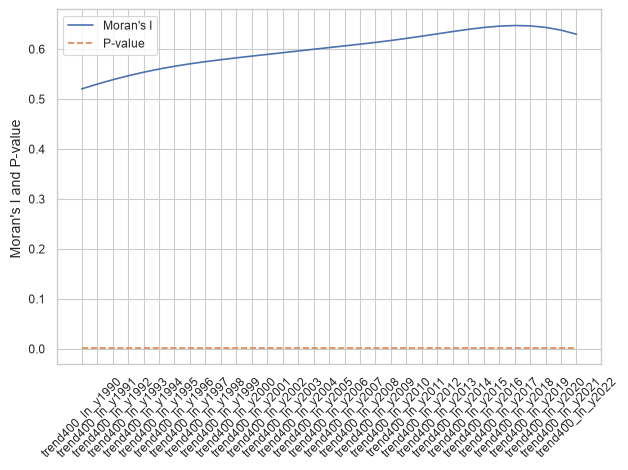

In [16]:
# Plot with significance level
def plot_moran_dynamics_with_significance_level(indicator_data):
    """
    Plot Moran's I and P-value dynamics.

    Parameters:
    - indicator_data: DataFrame or similar structure containing 'I' and 'I-P value' columns.

    Returns:
    None
    """
    # Plot 'I' values
    plt.plot(indicator_data.index, indicator_data['I'], label="Moran's I", linestyle='-')

    # Plot 'I-P value' values
    plt.plot(indicator_data.index, indicator_data['I-P value'], label='P-value', linestyle='--')

    # Adding labels and legend
    plt.xlabel("")
    plt.ylabel("Moran's I and P-value ")
    plt.legend()

    # Adjusting x-axis tick spacing
    plt.xticks(rotation=45)  # Rotate x-axis labels for better readability

    # Display the combined graph
    plt.tight_layout()  # Ensure all elements fit in the figure
    plt.show()

# Plot over the data
plot_moran_dynamics_with_significance_level(moran_dynamics_ratioW)

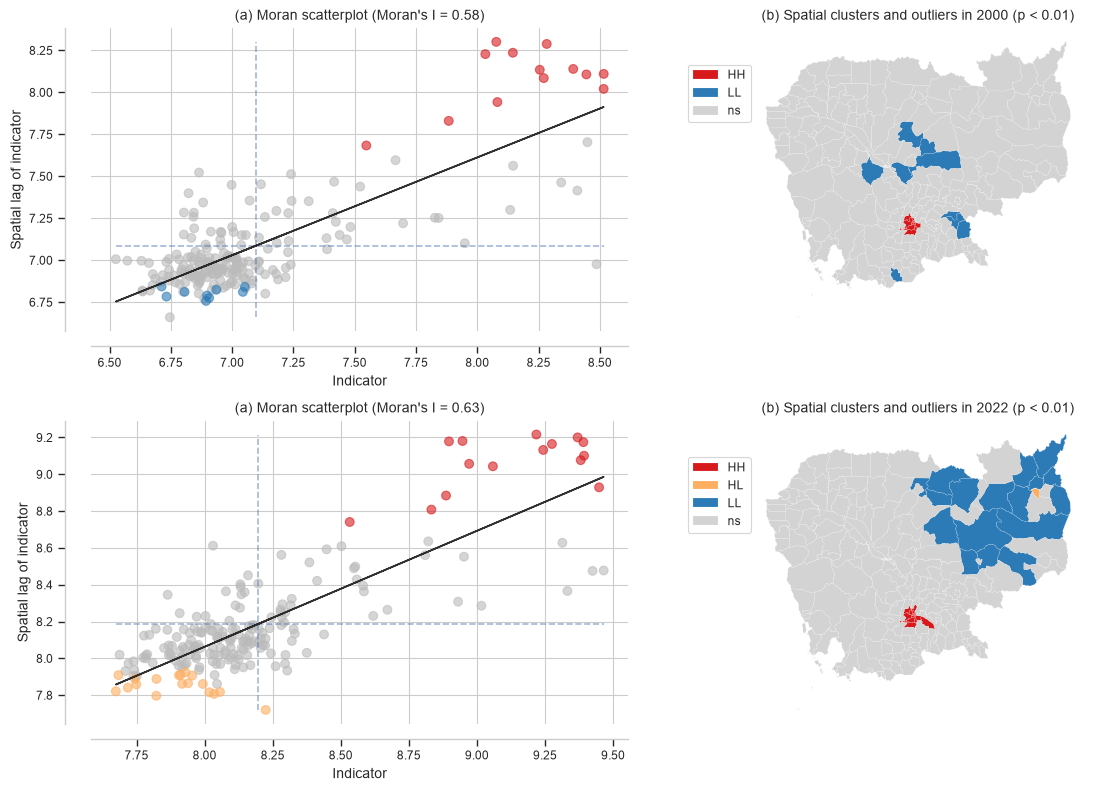

In [17]:
def visualize_spatial_association(gdf_INDICATOR, W, year_var, ax1, ax2):
    """
    Visualize spatial association using Moran's I and Local Indicators of Spatial Association (LISA).

    Parameters:
    - gdf_INDICATOR: GeoDataFrame containing the indicator data for the specified year.
    - W: Spatial weights matrix.
    - year_var: The specific variable name for which spatial association is visualized.
    - ax1, ax2: Matplotlib Axes objects where the plots will be drawn.

    Returns:
    None
    """
    # Extract year from variable name
    year = year_var.replace('trend400_ln_y', '')

    # Calculate global Moran's I
    globalMoran_INDICATOR = Moran(gdf_INDICATOR[year_var], W)
    MoranI_INDICATOR = "{:.2f}".format(globalMoran_INDICATOR.I)

    # Calculate local indicators of spatial association
    localMoran_INDICATOR = Moran_Local(gdf_INDICATOR[year_var], W, permutations=999, seed=12345)

    # Plotting Moran scatterplot
    moran_scatterplot(localMoran_INDICATOR, p=0.01, aspect_equal=False, zstandard=False, ax=ax1)

    # Plotting Local Indicators of Spatial Association (LISA) clusters
    lisa_cluster(localMoran_INDICATOR, gdf_INDICATOR, p=0.01, legend_kwds={'bbox_to_anchor': (0.02, 0.90)}, ax=ax2)

    # Setting labels and titles for the plots
    ax1.set_xlabel('Indicator')
    ax1.set_ylabel('Spatial lag of indicator')
    ax1.set_title(f"(a) Moran scatterplot (Moran's I = {MoranI_INDICATOR})")
    ax2.set_title(f"(b) Spatial clusters and outliers in {year} (p < 0.01)")

# Create a single figure with a 2x2 layout: one row per year
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

# Visualize spatial associations for different years, one row of the 2x2 layout each
visualize_spatial_association(gdf_wide, Wqueen, 'trend400_ln_y2000', axes[0, 0], axes[0, 1])
visualize_spatial_association(gdf_wide, Wqueen, 'trend400_ln_y2022', axes[1, 0], axes[1, 1])

# Adjust layout for better spacing
plt.tight_layout()

# Save the figure to a file
#plt.savefig('spatial_association_1x2png', dpi=300)

# Show the combined plot
plt.show()